[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_window_crash/BA_L4_window_crash.ipynb)

# BA_L4_window_crash: EWMA against a 30-day window around the March 2020 crash

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin volatility from February to May 2020 by three estimates available at the end of each day: the 30-day equal-weight standard deviation, the EWMA with decay 0.94 and the GARCH(1,1)-t forecast for the next day, annualised; the crash of 12 March 2020 enters all three at once and leaves the 30-day window on 11 April 2020, when that estimate falls by almost half in one day.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Bitcoin daily log returns in per cent (EODHD), 1 January 2018 – 18 September 2026; the chart shows February – May 2020.

**Method.** At the end of each day $t$: the standard deviation of $r_{t-29}, \dots, r_t$; the EWMA variance after the update with $r_t$, $\sigma^2 \leftarrow 0.94\,\sigma^2 + 0.06\,r_t^2$ (started at the variance of the first 250 days); and the GARCH(1,1)-t forecast $\sigma^2_{t+1}$. All annualised with $\sqrt{365}$.

**How to read.** Dotted lines: 12 March 2020 (return $-46.5\%$) and 11 April 2020, when the crash leaves the 30-day window.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


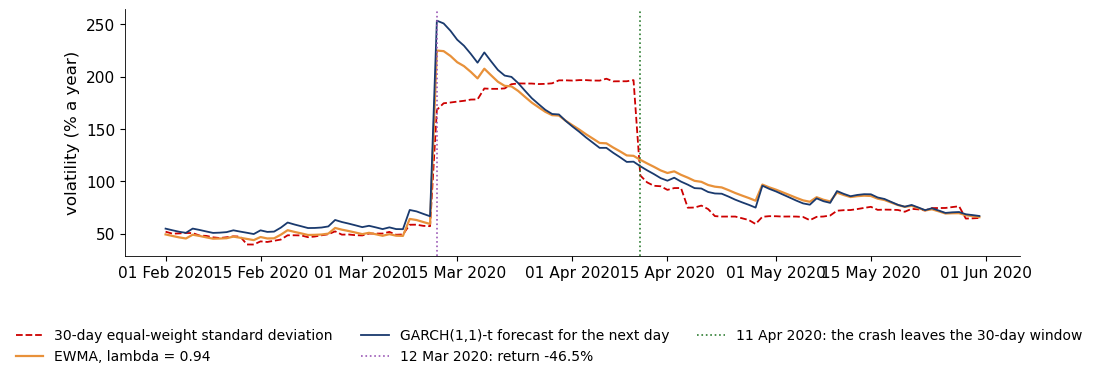

In [6]:
import matplotlib.dates as mdates
lam = 0.94
rb = R['Bitcoin']
gb_ = arch_model(rb, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
v_ = rb.iloc[:250].var(); ew_end = []
for x_ in rb.values:
    v_ = lam * v_ + (1 - lam) * x_ ** 2
    ew_end.append(v_)
ew_end = pd.Series(ew_end, index=rb.index)
roll30 = rb.rolling(30).std()
g_next = pd.Series(np.r_[gb_.conditional_volatility.values[1:] ** 2,
                         gb_.forecast(horizon=1, reindex=False).variance.values[-1, 0]], index=rb.index)
ann = lambda s2: np.sqrt(365 * s2)
w20 = slice('2020-02-01', '2020-05-31')
crash, drop = pd.Timestamp('2020-03-12'), pd.Timestamp('2020-03-12') + pd.Timedelta(days=30)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(roll30.loc[w20].index, ann(roll30.loc[w20] ** 2), color=RED, ls='--', lw=1.3, label='30-day equal-weight standard deviation')
ax.plot(ew_end.loc[w20].index, ann(ew_end.loc[w20]), color=BTC, lw=1.6, label='EWMA, lambda = 0.94')
ax.plot(g_next.loc[w20].index, ann(g_next.loc[w20]), color=BLUE, lw=1.3, label='GARCH(1,1)-t forecast for the next day')
ax.axvline(crash, color=ETH, ls=':', lw=1.2, label='12 Mar 2020: return -46.5%')
ax.axvline(drop, color=GREEN, ls=':', lw=1.2, label='11 Apr 2020: the crash leaves the 30-day window')
ax.set_ylabel('volatility (% a year)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.2, 1, 1))
save_fig(fig, 'ba_l4_window_crash')

**Key numbers** (as on the slide), % a year.

In [7]:
d_ = drop - pd.Timedelta(days=1); pk = ann(roll30.loc[w20] ** 2)
pd.Series({'EWMA, 12 Mar 2020': ann(ew_end[crash]), 'GARCH-t forecast made on 12 Mar 2020': ann(g_next[crash]),
           '30-day sd, 12 Mar 2020': ann(roll30[crash] ** 2), '30-day sd, peak': pk.max(), 'day of the 30-day peak': pk.idxmax().date(),
           '30-day sd, 10 Apr 2020': ann(roll30[d_] ** 2), '30-day sd, 11 Apr 2020': ann(roll30[drop] ** 2),
           'EWMA, 10 Apr 2020': ann(ew_end[d_]), 'EWMA, 11 Apr 2020': ann(ew_end[drop])}).to_frame('value')

,value
"EWMA, 12 Mar 2020",224.938273
GARCH-t forecast made on 12 Mar 2020,253.515163
"30-day sd, 12 Mar 2020",168.294367
"30-day sd, peak",198.021665
day of the 30-day peak,2020-04-06
"30-day sd, 10 Apr 2020",196.665285
"30-day sd, 11 Apr 2020",105.564027
"EWMA, 10 Apr 2020",124.338594
"EWMA, 11 Apr 2020",120.551532
